# Global YouTube Statistics — Exploratory Data Analysis

**Objective:** explore the profile and performance of the largest YouTube channels in the dataset, identify patterns in subscribers, views, channel categories and estimated earnings, and document data-quality limitations.

> This is an exploratory analysis, not a causal study. The dataset is a snapshot of selected channels; sums of subscribers across channels are not unique people, and earnings columns are estimates rather than verified revenue.

## 1. Questions guiding the analysis

1. Which categories have the most channels in this dataset?
2. How do subscribers and total video views relate?
3. Which countries account for the largest *sum of subscribers across listed channels*?
4. How do estimated monthly earnings vary by category?
5. What data-quality issues should be considered before interpreting results?

## 2. Load libraries and dataset

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

DATA_PATH = Path("Global YouTube Statistics.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Keep the CSV in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH, encoding="latin-1")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Rows: 995 | Columns: 28


,rank,Youtuber,subscribers,video views,category,Title,uploads,Country,Abbreviation,channel_type,...,subscribers_for_last_30_days,created_year,created_month,created_date,Gross tertiary education enrollment (%),Population,Unemployment rate,Urban_population,Latitude,Longitude
0,1,T-Series,245000000,2.280000e+11,Music,T-Series,20082,India,IN,Music,...,2000000.0,2006.0,Mar,13.0,28.1,1.366418e+09,5.36,471031528.0,20.593684,78.962880
1,2,YouTube Movies,170000000,0.000000e+00,Film & Animation,youtubemovies,1,United States,US,Games,...,NaN,2006.0,Mar,5.0,88.2,3.282395e+08,14.70,270663028.0,37.090240,-95.712891
2,3,MrBeast,166000000,2.836884e+10,Entertainment,MrBeast,741,United States,US,Entertainment,...,8000000.0,2012.0,Feb,20.0,88.2,3.282395e+08,14.70,270663028.0,37.090240,-95.712891
3,4,Cocomelon - Nursery Rhymes,162000000,1.640000e+11,Education,Cocomelon - Nursery Rhymes,966,United States,US,Education,...,1000000.0,2006.0,Sep,1.0,88.2,3.282395e+08,14.70,270663028.0,37.090240,-95.712891
4,5,SET India,159000000,1.480000e+11,Shows,SET India,116536,India,IN,Entertainment,...,1000000.0,2006.0,Sep,20.0,28.1,1.366418e+09,5.36,471031528.0,20.593684,78.962880


## 3. Data structure and quality

In [2]:
# Normalize column whitespace only; preserve original column names otherwise.
df.columns = df.columns.str.strip()

print("Column names:")
print(df.columns.tolist())

print("\\nData types and non-null counts:")
df.info()

quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_percent", ascending=False)

print(f"\\nExact duplicate rows: {df.duplicated().sum()}")
display(quality)

Column names:
['rank', 'Youtuber', 'subscribers', 'video views', 'category', 'Title', 'uploads', 'Country', 'Abbreviation', 'channel_type', 'video_views_rank', 'country_rank', 'channel_type_rank', 'video_views_for_the_last_30_days', 'lowest_monthly_earnings', 'highest_monthly_earnings', 'lowest_yearly_earnings', 'highest_yearly_earnings', 'subscribers_for_last_30_days', 'created_year', 'created_month', 'created_date', 'Gross tertiary education enrollment (%)', 'Population', 'Unemployment rate', 'Urban_population', 'Latitude', 'Longitude']
\nData types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 995 entries, 0 to 994
Data columns (total 28 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   rank                                     995 non-null    int64  
 1   Youtuber                                 995 non-null    str    
 2   subscribers                              9

,missing_count,missing_percent,dtype
subscribers_for_last_30_days,337,33.87,float64
Latitude,123,12.36,float64
Urban_population,123,12.36,float64
Longitude,123,12.36,float64
Population,123,12.36,float64
Gross tertiary education enrollment (%),123,12.36,float64
Unemployment rate,123,12.36,float64
Abbreviation,122,12.26,str
Country,122,12.26,str
country_rank,116,11.66,float64


### Data-quality decisions

- Missing values are **measured and reported**, not automatically replaced with zero. A missing value is not necessarily equivalent to zero.
- The notebook uses `dropna()` only within a specific chart or calculation when the required fields are missing; the original dataframe is preserved.
- Exact duplicate rows are checked, but that does not prove every channel record is unique in a business sense.
- Country-level subscriber sums describe the channels represented in this dataset, not the number of unique subscribers or the population of a country.
- `highest_monthly_earnings` is an estimated upper bound, not confirmed income.

## 4. Channel categories

,category,channel_count
0,Entertainment,241
1,Music,202
2,People & Blogs,132
3,Gaming,94
4,Comedy,69
5,Film & Animation,46
6,Unknown,46
7,Education,45
8,Howto & Style,40
9,News & Politics,26


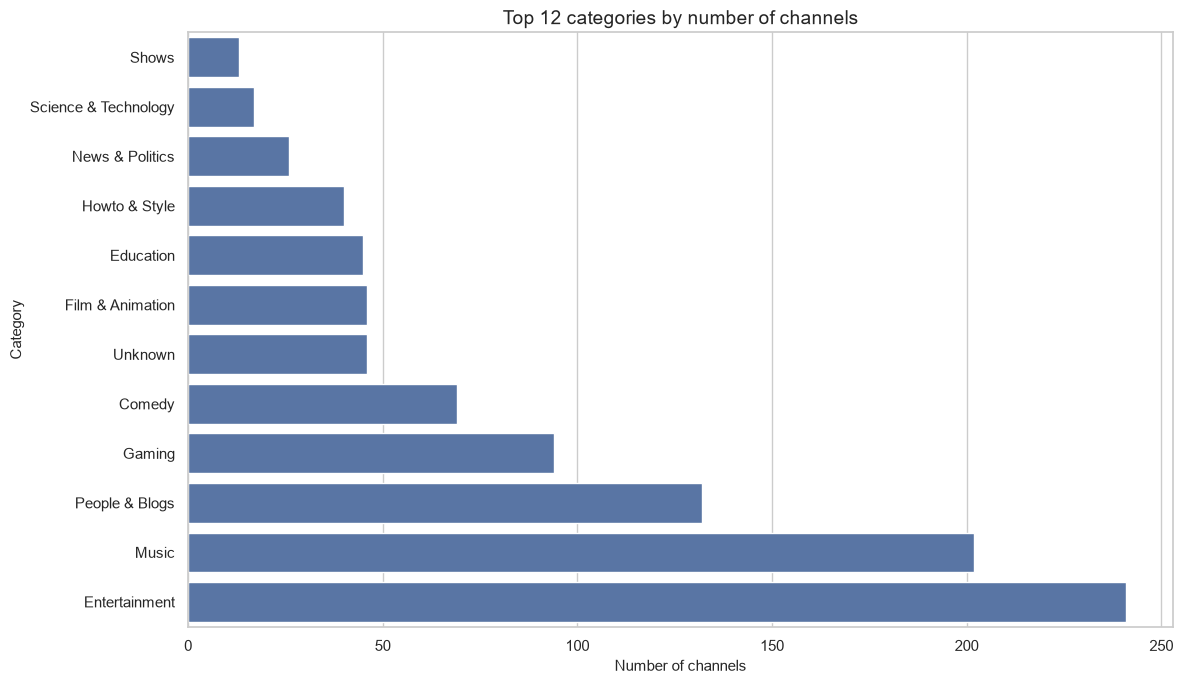

In [3]:
category_col = "category"
if category_col not in df.columns:
    raise KeyError(f"Expected column '{category_col}' was not found.")

category_counts = (
    df[category_col].fillna("Unknown")
    .value_counts()
    .rename_axis("category")
    .reset_index(name="channel_count")
)
display(category_counts.head(15))

plt.figure(figsize=(12, 7))
plot_data = category_counts.head(12).sort_values("channel_count")
sns.barplot(data=plot_data, x="channel_count", y="category")
plt.title("Top 12 categories by number of channels")
plt.xlabel("Number of channels")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

**How to interpret this chart:** it shows which categories are most represented in the dataset, not which categories are most popular among all YouTube users. The dataset's channel selection affects the result.

## 5. Subscribers and total video views

Spearman correlation between subscribers and total video views: 0.555
Spearman correlation measures the strength of a monotonic relationship; it does not establish causation.


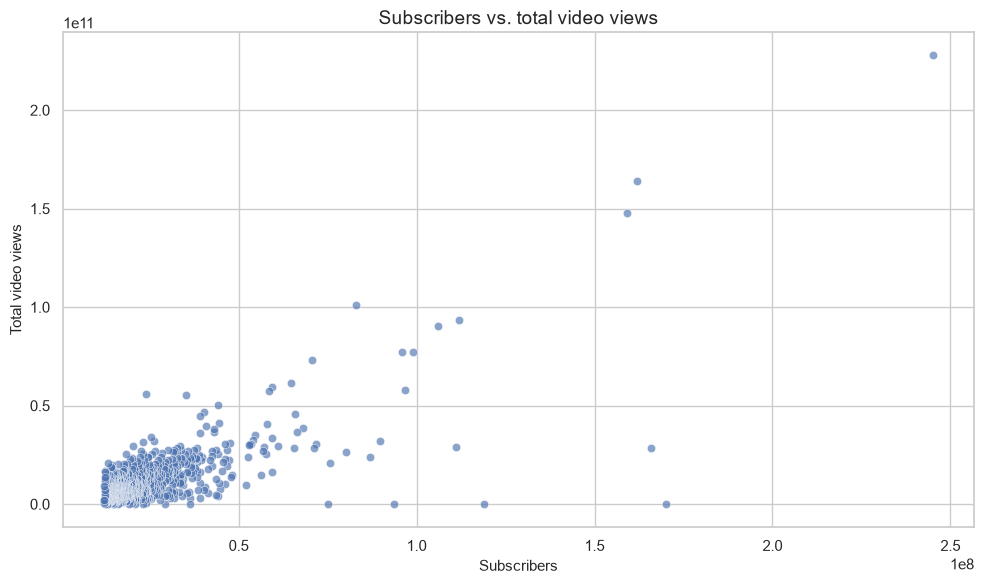

In [4]:
required = ["subscribers", "video views"]
missing = [col for col in required if col not in df.columns]
if missing:
    raise KeyError(f"Required columns not found: {missing}")

performance = df[required].copy()
for col in required:
    performance[col] = pd.to_numeric(performance[col], errors="coerce")
performance = performance.dropna()

correlation = performance["subscribers"].corr(performance["video views"], method="spearman")
print(f"Spearman correlation between subscribers and total video views: {correlation:.3f}")
print("Spearman correlation measures the strength of a monotonic relationship; it does not establish causation.")

plt.figure(figsize=(10, 6))
sns.scatterplot(data=performance, x="subscribers", y="video views", alpha=0.65)
plt.title("Subscribers vs. total video views")
plt.xlabel("Subscribers")
plt.ylabel("Total video views")
plt.tight_layout()
plt.show()

**How to interpret this chart:** a positive association would mean channels with more subscribers tend to also have more total views. The relationship can be influenced by channel age, upload volume, and outliers, so it should not be read as evidence that subscribers alone cause views.

## 6. Countries represented in the dataset

,Country,channel_count,subscribers_sum,subscribers_median
46,United States,313,7329500000,18300000.0
18,India,168,4310600000,17150000.0
6,Brazil,62,1221800000,15550000.0
45,United Kingdom,43,917400000,18800000.0
27,Mexico,33,626900000,16100000.0
19,Indonesia,28,534100000,17400000.0
37,South Korea,17,481700000,17700000.0
33,Russia,16,407200000,16500000.0
41,Thailand,18,386500000,16900000.0
38,Spain,22,385100000,15000000.0


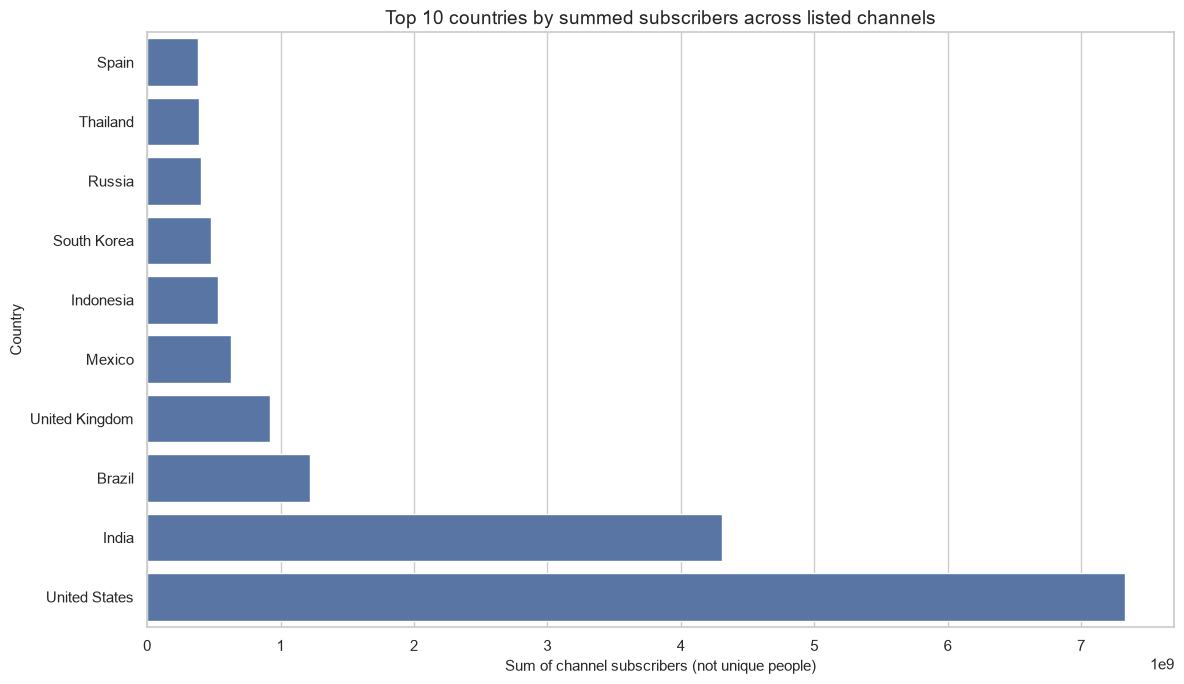

In [5]:
country_col = "Country"
if country_col not in df.columns:
    raise KeyError(f"Expected column '{country_col}' was not found.")

country_data = df[["Country", "subscribers"]].copy()
country_data["subscribers"] = pd.to_numeric(country_data["subscribers"], errors="coerce")
country_data = country_data.dropna(subset=["Country", "subscribers"])

country_summary = (
    country_data.groupby("Country", as_index=False)
    .agg(channel_count=("subscribers", "size"),
         subscribers_sum=("subscribers", "sum"),
         subscribers_median=("subscribers", "median"))
    .sort_values("subscribers_sum", ascending=False)
)

display(country_summary.head(10))

top_countries = country_summary.head(10).sort_values("subscribers_sum")
plt.figure(figsize=(12, 7))
sns.barplot(data=top_countries, x="subscribers_sum", y="Country")
plt.title("Top 10 countries by summed subscribers across listed channels")
plt.xlabel("Sum of channel subscribers (not unique people)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

**How to interpret this chart:** this comparison is affected by how many channels from each country appear in the dataset. For a fairer comparison, inspect `channel_count` and `subscribers_median` in the table alongside the total.

## 7. Estimated monthly earnings by category

,category,channel_count,median_estimated_monthly_upper_bound,mean_estimated_monthly_upper_bound
0,Autos & Vehicles,2,1086350.0,1.086350e+06
14,Shows,13,540100.0,2.037662e+06
9,News & Politics,26,493300.0,6.426320e+05
7,Movies,2,454700.0,4.547000e+05
10,Nonprofits & Activism,2,390400.0,3.904000e+05
16,Trailers,2,361900.0,3.619000e+05
8,Music,202,353550.0,5.522996e+05
15,Sports,11,339500.0,8.069364e+05
2,Education,45,334800.0,6.951778e+05
4,Film & Animation,46,232600.0,7.327018e+05


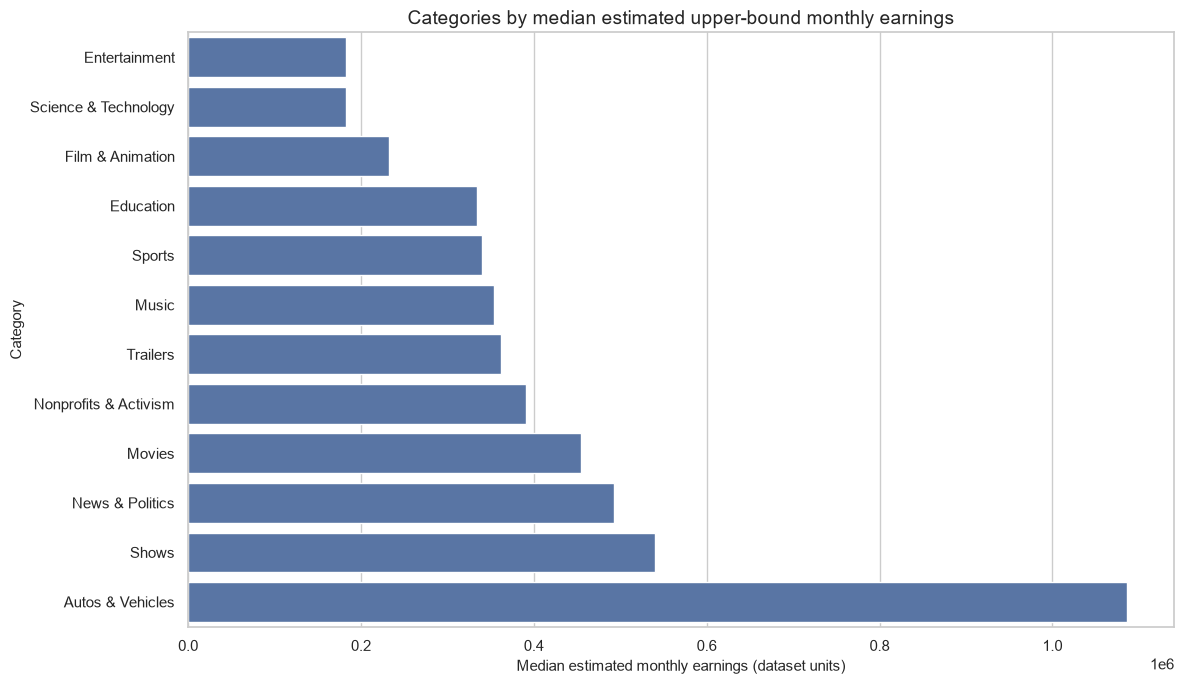

In [6]:
earnings_col = "highest_monthly_earnings"
if earnings_col not in df.columns:
    raise KeyError(f"Expected column '{earnings_col}' was not found.")

earnings = df[["category", earnings_col]].copy()
earnings[earnings_col] = pd.to_numeric(earnings[earnings_col], errors="coerce")
earnings = earnings.dropna(subset=[earnings_col])
earnings["category"] = earnings["category"].fillna("Unknown")

earnings_summary = (
    earnings.groupby("category", as_index=False)
    .agg(channel_count=(earnings_col, "count"),
         median_estimated_monthly_upper_bound=(earnings_col, "median"),
         mean_estimated_monthly_upper_bound=(earnings_col, "mean"))
    .sort_values("median_estimated_monthly_upper_bound", ascending=False)
)

display(earnings_summary.head(15))

top_earnings_categories = (
    earnings_summary.head(12)
    .sort_values("median_estimated_monthly_upper_bound")
)
plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_earnings_categories,
    x="median_estimated_monthly_upper_bound",
    y="category"
)
plt.title("Categories by median estimated upper-bound monthly earnings")
plt.xlabel("Median estimated monthly earnings (dataset units)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

**Why use the median?** estimated earnings can be strongly skewed by a few very large channels. The median is less sensitive to extreme values than the mean. These are still estimates and should not be described as actual revenue.

## 8. Creation year and channel age

,created_year,channel_count,median_subscribers,mean_subscribers
4,2008.0,46,17900000.0,2.365217e+07
5,2009.0,52,19200000.0,2.310577e+07
6,2010.0,48,15900000.0,2.067083e+07
7,2011.0,82,18250000.0,2.180000e+07
8,2012.0,68,17300000.0,2.403824e+07
9,2013.0,76,19700000.0,2.452763e+07
10,2014.0,98,17350000.0,2.061837e+07
11,2015.0,73,16300000.0,2.124795e+07
12,2016.0,77,17500000.0,2.310130e+07
13,2017.0,68,15950000.0,1.866618e+07


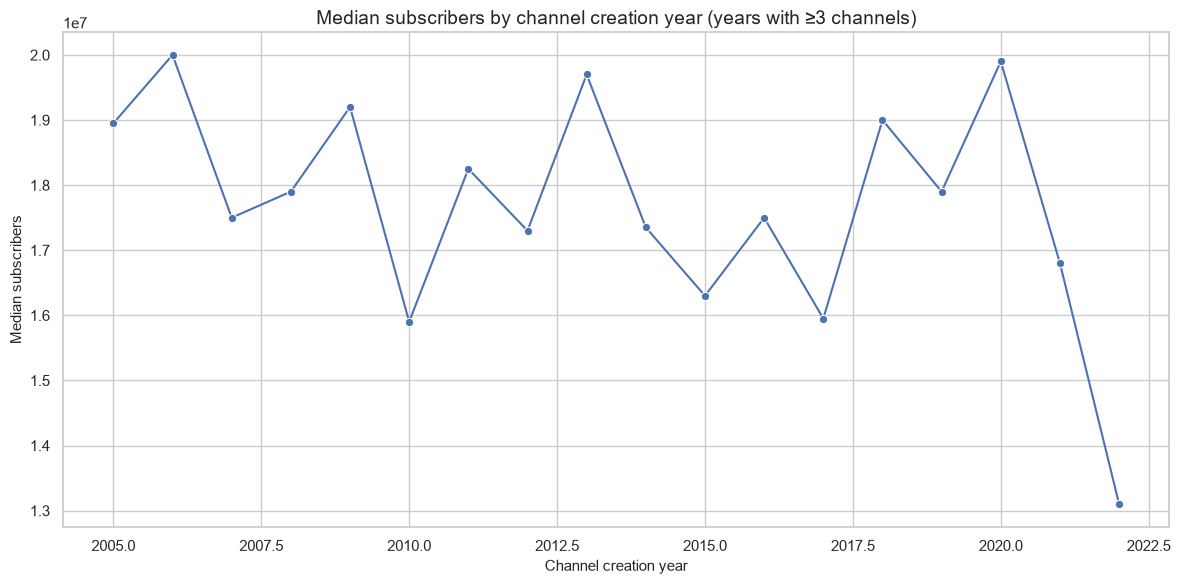

In [7]:
year_col = "created_year"
if year_col in df.columns:
    year_data = df[[year_col, "subscribers"]].copy()
    year_data[year_col] = pd.to_numeric(year_data[year_col], errors="coerce")
    year_data["subscribers"] = pd.to_numeric(year_data["subscribers"], errors="coerce")
    year_data = year_data.dropna()

    year_summary = (
        year_data.groupby(year_col, as_index=False)
        .agg(channel_count=("subscribers", "size"),
             median_subscribers=("subscribers", "median"),
             mean_subscribers=("subscribers", "mean"))
        .sort_values(year_col)
    )
    display(year_summary.tail(15))

    # Show recent creation years with enough records to avoid overemphasizing tiny groups.
    chart_data = year_summary[year_summary["channel_count"] >= 3].tail(20)
    if not chart_data.empty:
        plt.figure(figsize=(12, 6))
        sns.lineplot(data=chart_data, x=year_col, y="median_subscribers", marker="o")
        plt.title("Median subscribers by channel creation year (years with ≥3 channels)")
        plt.xlabel("Channel creation year")
        plt.ylabel("Median subscribers")
        plt.tight_layout()
        plt.show()
else:
    print(f"Column '{year_col}' not found; skipping this analysis.")

**Caution:** this is a cross-sectional comparison of channels created in different years, not a longitudinal growth study. Older channels have had more time to accumulate views and subscribers, and the number of channels per year varies.

## 9. Key findings — generated from the data

In [8]:
# Print concise, reproducible findings rather than hard-coding conclusions.
print(f"Dataset size: {len(df):,} channel records and {df.shape[1]} columns.")
print(f"Exact duplicate rows: {df.duplicated().sum():,}.")
print(f"Columns with missing values: {(df.isna().sum() > 0).sum():,}.")

if not category_counts.empty:
    top_category = category_counts.iloc[0]
    print(f"Most represented category: {top_category['category']} ({int(top_category['channel_count'])} channels).")

if not country_summary.empty:
    top_country = country_summary.iloc[0]
    print(
        f"Highest summed subscribers among listed channels: {top_country['Country']} "
        f"({top_country['subscribers_sum']:,.0f} subscribers across "
        f"{int(top_country['channel_count'])} listed channels)."
    )

if not earnings_summary.empty:
    top_earnings = earnings_summary.iloc[0]
    print(
        f"Highest category median estimated monthly upper bound: {top_earnings['category']} "
        f"({top_earnings['median_estimated_monthly_upper_bound']:,.2f}; "
        f"n={int(top_earnings['channel_count'])})."
    )

print("\\nThese are descriptive findings for this dataset only. Check sample sizes and missingness before drawing broader conclusions.")

Dataset size: 995 channel records and 28 columns.
Exact duplicate rows: 0.
Columns with missing values: 18.
Most represented category: Entertainment (241 channels).
Highest summed subscribers among listed channels: United States (7,329,500,000 subscribers across 313 listed channels).
Highest category median estimated monthly upper bound: Autos & Vehicles (1,086,350.00; n=2).
\nThese are descriptive findings for this dataset only. Check sample sizes and missingness before drawing broader conclusions.


## 10. Conclusions and limitations

This exploration examines channel representation by category, the association between subscribers and total views, country representation, estimated monthly earnings, and creation-year patterns. The notebook intentionally avoids treating summed subscribers as unique users or estimated earnings as verified revenue.

### Limitations
- The dataset represents a selected set of channels and may not be representative of all YouTube channels.
- Missing data may affect comparisons, especially for country and recent subscriber metrics.
- Correlation does not imply causation.
- Estimated earnings are not verified financial results.
- Country totals depend on how many channels from each country are included.

### Possible next steps
- Compare categories using medians and sample sizes, not means alone.
- Investigate missingness patterns before modelling.
- Add confidence intervals or robust statistical comparisons when a clear research question is defined.
- Document the original dataset source and license if known.